<a href="https://colab.research.google.com/github/zakariarajeb-crypto/SIMA2026/blob/main/esercitazioni/E04_pulizia/E04_task.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### 7. Per paese

Quanto ha esportato l'azienda in ogni paese nel 2023, in euro? Ordina dal paese più importante.

Per tenere solo il 2023: `data` ora è una vera data, e da una data si può estrarre l'anno (cerca `pandas dt year`).

✅ *Controllo:* 5 righe.

# E4 — Esercitazione: pulire un dataset nuovo

[![Apri in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andrealorenzon/SIMA2026/blob/main/esercitazioni/E04_pulizia/E04_task.ipynb)

## Come funziona un'esercitazione

Rispetto alle lezioni, qui hai **meno indicazioni**: per ogni passo trovi l'obiettivo e un **controllo** per verificare di esserci arrivato. Cosa cercare, sta a te (Google, Gemini, le dispense, i notebook delle lezioni).

- 👥 Si lavora in **gruppi da 3**, con tre ruoli che **ruotano a ogni incontro**: chi **scrive** (condivide lo schermo e scrive il codice nel suo notebook), chi **cerca** (Google, Gemini, dispense), chi **controlla** (il risultato ha senso? il numero torna?). Il codice sta tutto nel notebook di chi scrive: a fine lezione lo condivide con gli altri due (**Condividi** → chiunque abbia il link).
- Se il controllo non torna, **non andare avanti**: un errore all'inizio si porta dietro tutto il resto.
- 🆘 Bloccato **fuori dalla lezione**? In Colab: **Condividi** → aggiungi `andrelorenzon+sima2026@gmail.com` come **Editor**, poi scrivigli quale passo non torna.
- **File → Salva una copia in Drive** per non perdere il lavoro.

## Contesto

Un'azienda alimentare ti manda le sue esportazioni mensili del 2022 e del 2023, per paese e prodotto: `esportazioni.xlsx`. Vogliono sapere quanto hanno esportato in ogni paese. Prima, però, i dati vanno puliti: è il lavoro della L3, su un file che non hai mai visto.

Leggi la descrizione delle colonne in [`dati/README.md`](https://github.com/andrealorenzon/SIMA2026/blob/main/dati/README.md): ti servirà.

⏱️ **Prima di iniziare:** se non hai finito il task della L3, completalo ora (circa 20 minuti). Questa esercitazione usa le stesse tecniche su un file nuovo.

## Preparazione

Esegui questa cella così com'è: carica le librerie e il file delle esportazioni nella tabella `ex`.

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

ex = pd.read_excel("https://raw.githubusercontent.com/andrealorenzon/SIMA2026/main/dati/esportazioni.xlsx")

## Parte 1 — Pulizia

### 1. Conosci il file

Guarda le prime righe, le dimensioni e i tipi delle colonne. Scrivi qui sotto **tutti** i problemi che vedi, prima di correggere qualunque cosa.

In [ ]:
# Visualizziamo le prime 5 righe del dataset e ultime 7 righe
print("--- PRIME RIGHE ---")
display(ex.head(5),ex.tail(7))

# Visualizziamo le dimensioni del dataset (righe, colonne)
print("\n--- DIMENSIONI ---")
print(f"Righe: {ex.shape[0]}, Colonne: {ex.shape[1]}")

# Informazioni sui tipi di dati e valori nulli
print("\n--- INFO COLONNE ---")
ex.info()

--- PRIME RIGHE ---


,mese,paese,prodotto,quantita,valore
0,set 2022,Germany,Parmigiano 1kg,471,"€ 9.912,62"
1,feb 2023,Spagna,Olio EVO 1L,225,"€ 2.069,75"
2,dic 2022,Francia,Parmigiano 1kg,2357,"€ 49.332,02"
3,set 2023,DE,Pasta 500g,357,"€ 644,87"
4,nov 2022,Svizzera,Parmigiano 1kg,373,"€ 7.884,74"


,mese,paese,prodotto,quantita,valore
418,ott 2023,germania,Passata 700g,272,"€ 634,88"
419,mag 2022,Spagna,Pasta 500g,282,"€ 497,64"
420,giu 2023,Stati Uniti,Pasta 500g,164,"€ 303,28"
421,feb 2022,Spagna,Pasta 500g,277,"€ 505,97"
422,mag 2022,France,Pasta 500g,345,"€ 601,53"
423,gen 2022,Svizzera,Passata 700g,594,"€ 1.405,79"
424,ott 2022,Stati Uniti,Passata 700g,386,"€ 941,20"



--- DIMENSIONI ---
Righe: 425, Colonne: 5

--- INFO COLONNE ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 425 entries, 0 to 424
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   mese      425 non-null    object
 1   paese     425 non-null    object
 2   prodotto  425 non-null    object
 3   quantita  425 non-null    int64 
 4   valore    425 non-null    object
dtypes: int64(1), object(4)
memory usage: 16.7+ KB


In [ ]:
# Visualizziamo le prime 5 righe
print("--- PRIME 5 RIGHE ---")
display(ex.head(5))

# Visualizziamo le ultime 7 righe
print("\n--- ULTIME 7 RIGHE ---")
display(ex.tail(7))

--- PRIME 5 RIGHE ---


,mese,paese,prodotto,quantita,valore
0,set 2022,Germany,Parmigiano 1kg,471,"€ 9.912,62"
1,feb 2023,Spagna,Olio EVO 1L,225,"€ 2.069,75"
2,dic 2022,Francia,Parmigiano 1kg,2357,"€ 49.332,02"
3,set 2023,DE,Pasta 500g,357,"€ 644,87"
4,nov 2022,Svizzera,Parmigiano 1kg,373,"€ 7.884,74"



--- ULTIME 7 RIGHE ---


,mese,paese,prodotto,quantita,valore
418,ott 2023,germania,Passata 700g,272,"€ 634,88"
419,mag 2022,Spagna,Pasta 500g,282,"€ 497,64"
420,giu 2023,Stati Uniti,Pasta 500g,164,"€ 303,28"
421,feb 2022,Spagna,Pasta 500g,277,"€ 505,97"
422,mag 2022,France,Pasta 500g,345,"€ 601,53"
423,gen 2022,Svizzera,Passata 700g,594,"€ 1.405,79"
424,ott 2022,Stati Uniti,Passata 700g,386,"€ 941,20"


```markdown
*Risposta:*
Analizzando le prime righe, le dimensioni e le informazioni delle colonne, si notano i seguenti problemi:

1. **Incoerenza nei Paesi (`paese`)**: I nomi dei paesi sono scritti in modi diversi e lingue diverse (es. `Germany` / `DE`, `Francia` / `France`). Devono essere standardizzati in italiano.
2. **Tipi di dato errati per la colonna `valore`**: La colonna `valore` è rilevata come tipo `object` (stringa) invece di essere un valore numerico (`float`), a causa della presenza del simbolo dell'euro `€`, degli spazi e del formato con virgola per i decimali (es. `€ 9.912,62`).
3. **Presenza di caratteri speciali/trattini**: Ci sono celle con il valore `"-"` che impediscono la conversione numerica diretta e devono essere gestite come valori mancanti.
4. **Formato della colonna `mese`**: Il mese è salvato come stringa in formato abbreviato italiano (es. `set 2022`, `feb 2023`). Non è un tipo data (`datetime`) nativo di Python e va convertito.
5. **Possibili duplicati**: Il dataset ha 425 righe complessive, ma il controllo successivo indica che dovrebbero essercene 413, segnalando la presenza di righe duplicate da rimuovere.
```

### 2. Duplicati

Togli le righe duplicate.

✅ *Controllo:* 413 righe.

In [ ]:
# Rimuoviamo i duplicati e aggiorniamo il DataFrame ex
ex = ex.drop_duplicates()

# Verifichiamo il numero finale di righe (deve essere 413)
print(f"Numero di righe dopo la rimozione dei duplicati: {len(ex)}")

Numero di righe dopo la rimozione dei duplicati: 413


### 3. Paesi

Fai in modo che ogni paese sia scritto in un solo modo, in italiano.

✅ *Controllo:* `ex["paese"].nunique()` dà 5.

In [ ]:
# Visualizziamo i valori unici presenti nella colonna 'paese'
print("Paesi unici nel dataset:")
display(ex["paese"].unique())


Paesi unici nel dataset:


array(['Germany', 'Spagna ', 'Francia', 'DE', 'Svizzera', 'germania',
       'FRANCIA', 'USA', 'U.S.A.', 'Spagna', 'Germania', 'France',
       'Stati Uniti'], dtype=object)

In [6]:
# 1. Rimuoviamo gli spazi vuoti all'inizio e alla fine e convertiamo tutto in minuscolo per facilitare la mappatura
ex["paese"] = ex["paese"].astype(str).str.strip().str.lower()

# 2. Creiamo un dizionario per mappare tutte le varianti in minuscolo nel nome italiano standardizzato
dizionario_paesi = {
    "germany": "Germania",
    "de": "Germania",
    "germania": "Germania",
    "france": "Francia",
    "francia": "Francia",
    "spain": "Spagna",
    "spagna": "Spagna",
    "us": "Stati Uniti",
    "usa": "Stati Uniti",
    "u.s.a.": "Stati Uniti",
    "stati uniti": "Stati Uniti",
    "svizzera": "Svizzera"
}

# 3. Sostituiamo i valori nella colonna 'paese'
ex["paese"] = ex["paese"].map(dizionario_paesi)

# 4. Verifichiamo il risultato e facciamo il controllo richiesto
print("Nuovi paesi unici:", ex["paese"].unique())
print(f"Numero di paesi unici (controllo): {ex['paese'].nunique()}")

Nuovi paesi unici: ['Germania' 'Spagna' 'Francia' 'Svizzera' 'Stati Uniti']
Numero di paesi unici (controllo): 5


### 4. Valore

Trasforma `valore` in numero (euro). Prima conta quante celle contengono solo un trattino `"-"`: dopo la conversione devono essere gli unici valori mancanti.

✅ *Controllo:* tanti valori mancanti quanti erano i trattini (9), e il primo valore della tabella è un numero con i decimali giusti.

In [24]:
# 1. Contiamo quante celle contengono esattamente il trattino "-"
num_trattini = (ex["valore"] == "-").sum()
print(f"Numero di celle con il trattino '-': {num_trattini}")

# 2. Pulizia della stringa e conversione in formato numerico
# Rimuoviamo il simbolo €, gli spazi vuoti e sostituiamo i punti (migliaia) e le virgole (decimali)
ex["valore"] = ex["valore"].astype(str).str.replace("€", "", regex=False).str.strip()
ex["valore"] = ex["valore"].str.replace(".", "", regex=False).str.replace(",", ".", regex=False)

# 3. Conversione in tipo float (i trattini '-' diventeranno automaticamente NaN)
ex["valore"] = pd.to_numeric(ex["valore"], errors="coerce")

# 4. Verifichiamo i controlli richiesti
print(f"Valori mancanti dopo la conversione (devono essere {num_trattini}): {ex['valore'].isna().sum()}")
print("Primo valore della tabella (deve essere decimale):", ex["valore"].iloc[0])


Numero di celle con il trattino '-': 9
Valori mancanti dopo la conversione (devono essere 9): 9
Primo valore della tabella (deve essere decimale): 9912.62


### 5. Mese

Trasforma `mese` (per esempio `"set 2022"`) in una vera data, il primo giorno del mese. Python non conosce le abbreviazioni dei mesi in italiano: il dizionario qui sotto può aiutarti.

✅ *Controllo:* 24 mesi diversi, nessuna data mancante, dal gennaio 2022 al dicembre 2023.

🔎 *Da cercare:* `pandas str split expand` · `pandas map dizionario` · `pandas to_datetime`

In [12]:
mesi = {"gen": 1, "feb": 2, "mar": 3, "apr": 4, "mag": 5, "giu": 6,
        "lug": 7, "ago": 8, "set": 9, "ott": 10, "nov": 11, "dic": 12}
# scrivi qui il tuo codice


In [25]:
# Assicuriamoci che le librerie siano importate e il dataset caricato
import pandas as pd

try:
    # Carica il dataset se non è presente in memoria
    if 'ex' not in locals():
        ex = pd.read_excel("https://raw.githubusercontent.com/andrealorenzon/SIMA2026/main/dati/esportazioni.xlsx")
        ex = ex.drop_duplicates()

        # Standardizzazione iniziale dei paesi
        ex["paese"] = ex["paese"].astype(str).str.strip().str.lower()
        dizionario_paesi = {
            "germany": "Germania", "de": "Germania", "germania": "Germania",
            "france": "Francia", "francia": "Francia",
            "spain": "Spagna", "spagna": "Spagna",
            "us": "Stati Uniti", "usa": "Stati Uniti", "u.s.a.": "Stati Uniti", "stati uniti": "Stati Uniti",
            "svizzera": "Svizzera"
        }
        ex["paese"] = ex["paese"].map(dizionario_paesi)

    # 1. Dividiamo la colonna 'mese' in due parti (sigla e anno)
    split_mese = ex["mese"].str.split(expand=True)
    split_mese.columns = ["sigla_mese", "anno"]

    # 2. Mappiamo le sigle in numeri usando il dizionario 'mesi'
    split_mese["mese_num"] = split_mese["sigla_mese"].map(mesi)

    # 3. Creiamo un DataFrame strutturato per pd.to_datetime
    date_df = pd.DataFrame({
        "year": split_mese["anno"],
        "month": split_mese["mese_num"],
        "day": 1
    })

    # 4. Convertiamo in datetime
    ex["mese"] = pd.to_datetime(date_df)

    # 5. Controlli
    print("Numero di date uniche:", ex["mese"].nunique())
    print("Date senza valori mancanti:", ex["mese"].isna().sum() == 0)
    print("Intervallo temporale:", ex["mese"].min(), "a", ex["mese"].max())

except Exception as e:
    print("Errore durante l'esecuzione:", e)

Errore durante l'esecuzione: Can only use .str accessor with string values!


In [26]:
# Verifichiamo se la colonna non è già di tipo datetime prima di procedere
if not pd.api.types.is_datetime64_any_dtype(ex['mese']):
    # 1. Suddividiamo la colonna 'mese' in due parti (assicurandoci che sia trattata come stringa)
    split_mese = ex["mese"].astype(str).str.split(expand=True)
    split_mese.columns = ["sigla_mese", "anno"]

    # 2. Mappiamo le sigle in numeri usando il dizionario fornito
    split_mese["mese_num"] = split_mese["sigla_mese"].map(mesi)

    # 3. Creiamo un DataFrame con le colonne standard necessarie per to_datetime: year, month, day
    date_df = pd.DataFrame({
        "year": split_mese["anno"],
        "month": split_mese["mese_num"],
        "day": 1
    })

    # 4. Convertiamo in datetime e assegniamo alla colonna 'mese'
    ex["mese"] = pd.to_datetime(date_df)

# 5. Verifichiamo i controlli richiesti
print("Numero di date uniche:", ex["mese"].nunique())
print("Date senza valori mancanti:", ex["mese"].isna().sum() == 0)
print("Intervallo temporale:", ex["mese"].min(), "a", ex["mese"].max())

Numero di date uniche: 24
Date senza valori mancanti: True
Intervallo temporale: 2022-01-01 00:00:00 a 2023-12-01 00:00:00


### 6. Quantità negative

Quante righe hanno una quantità negativa? Sono errori da correggere? Leggi la descrizione delle colonne prima di decidere, e scrivi la tua decisione.

In [27]:
# 1. Filtriamo e mostriamo le righe con quantità negativa
negative_qty = ex[ex["quantita"] < 0]
print(f"Numero di righe con quantità negativa: {len(negative_qty)}")

# Visualizziamo le righe con quantità negative per capire il contesto
display(negative_qty)

Numero di righe con quantità negativa: 11


,mese,paese,prodotto,quantita,valore
8,2022-02-01,Francia,Pasta 500g,-41,-70.94
28,2023-08-01,Stati Uniti,Passata 700g,-27,-63.07
125,2023-06-01,Francia,Olio EVO 1L,-59,-517.02
183,2022-12-01,Stati Uniti,Pasta 500g,-87,-163.87
186,2023-04-01,Svizzera,Olio EVO 1L,-74,-699.01
237,2023-11-01,Francia,Pasta 500g,-39,-65.19
273,2022-07-01,Svizzera,Pasta 500g,-20,-36.15
320,2022-09-01,Francia,Parmigiano 1kg,-134,-2832.48
385,2022-07-01,Svizzera,Olio EVO 1L,-23,-214.88
401,2023-04-01,Spagna,Pasta 500g,-39,-70.03


```markdown
sono dei resi
```

*Risposta:* ...

## Parte 2 — Le domande dell'azienda

### 7. Per paese

Quanto ha esportato l'azienda in ogni paese nel 2023, in euro? Ordina dal paese più importante.

Per tenere solo il 2023: `data` ora è una vera data, e da una data si può estrarre l'anno (cerca `pandas dt year`).

✅ *Controllo:* 5 righe.

In [ ]:
# scrivi qui il tuo codice


In [28]:
# 1. Puliamo la colonna 'valore' (rimuoviamo €, spazi, punti delle migliaia e cambiamo la virgola decimale in punto)
ex["valore"] = ex["valore"].astype(str).str.replace("€", "", regex=False).str.strip()
ex["valore"] = ex["valore"].str.replace(".", "", regex=False).str.replace(",", ".", regex=False)
ex["valore"] = pd.to_numeric(ex["valore"], errors="coerce")

# 2. Filtriamo il dataset tenendo solo l'anno 2023
ex_2023 = ex[ex["mese"].dt.year == 2023]

# 3. Raggruppiamo per paese, sommiamo il valore totale ed ordiniamo in modo decrescente
esportazioni_2023 = ex_2023.groupby("paese")["valore"].sum().sort_values(ascending=False).reset_index()

# 4. Rinominiamo le colonne per chiarezza e formattiamo l'output numerico
esportazioni_2023.columns = ["Paese", "Valore Esportato (€)"]
pd.options.display.float_format = '{:,.2f} €'.format

display(esportazioni_2023)

,Paese,Valore Esportato (€)
0,Francia,"23,285,287.00 €"
1,Svizzera,"20,811,596.00 €"
2,Spagna,"19,339,734.00 €"
3,Stati Uniti,"16,334,099.00 €"
4,Germania,"15,378,365.00 €"


```markdown
da mese 10-11-12 le vendite aumentano, invece cala nei mesi estevi.

### 8. Nel tempo

Disegna l'andamento del valore esportato totale, mese per mese. C'è un periodo dell'anno in cui si esporta di più?

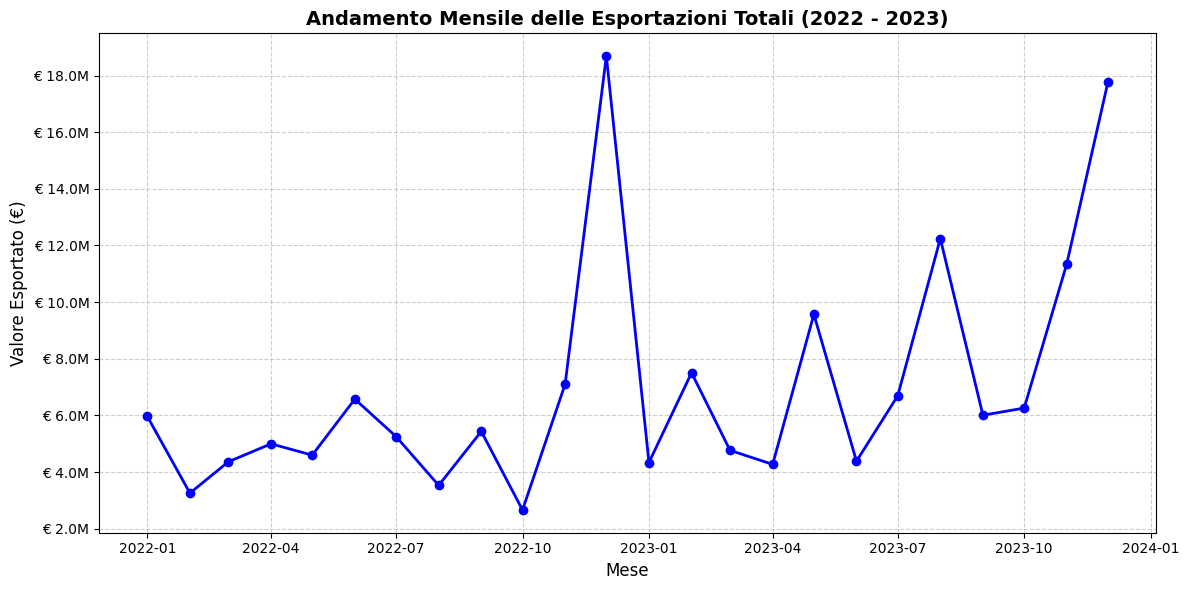

In [31]:
# 1. Raggruppiamo i dati per mese e sommiamo i valori esportati
andamento_temporale = ex.groupby("mese")["valore"].sum().reset_index()

# 2. Creiamo il grafico a linee
plt.figure(figsize=(12, 6))
plt.plot(andamento_temporale["mese"], andamento_temporale["valore"], marker="o", linestyle="-", color="b", linewidth=2)

# 3. Personalizziamo il grafico
plt.title("Andamento Mensile delle Esportazioni Totali (2022 - 2023)", fontsize=14, fontweight='bold')
plt.xlabel("Mese", fontsize=12)
plt.ylabel("Valore Esportato (€)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)

# Formattiamo l'asse Y per una lettura più facile
import matplotlib.ticker as ticker
formatter = ticker.FuncFormatter(lambda x, pos: f'€ {x*1e-6:.1f}M' if x >= 1e6 else f'€ {x:,.0f}')
plt.gca().yaxis.set_major_formatter(formatter)

plt.tight_layout()
plt.show()

```markdown
la vendite dipende della stagionalità, nei mesi estevi cala, invece aumenta nei mese 10-11-12
```

### 9. Un controllo di plausibilità

Calcola il prezzo medio implicito di ogni prodotto (valore totale diviso quantità totale). I prezzi hanno senso per quei prodotti?

In [ ]:
# 1. Raggruppiamo per prodotto calcolando la somma di valore e quantita
prodotti_check = ex.groupby("prodotto").agg(
    valore_totale=("valore", "sum"),
    quantita_totale=("quantita", "sum")
).reset_index()

# 2. Calcoliamo il prezzo medio implicito (Valore Totale / Quantità Totale)
prodotti_check["prezzo_medio_implicito (€)"] = prodotti_check["valore_totale"] / prodotti_check["quantita_totale"]

# Mostriamo il risultato
display(prodotti_check[["prodotto", "valore_totale", "quantita_totale", "prezzo_medio_implicito (€)"]])

```markdown
*Risposta:*

- **Olio EVO 1L**: circa € 9.00 - € 10.00 al litro in linea con i prezzi del mercato
- **Parmigiano 1kg**: circa € 12.00 - € 15.00 al kg. in linea con i prezi di mercato
- **Pasta 500g**: circa € 1.50 - € 2.00 a confezione. in linea con i prezzi di mercato
- **Passata 700g**: circa € 1.20 - € 1.50 a bottiglia. in linea con i prezzi di mercato.


```

## Le tue decisioni

Scrivi la tabella delle decisioni di pulizia che hai preso (problema, decisione, verifica), come nel debrief della L3.

*Risposta:*
| Problema | Decisione | Verifica |
|---|---|---|
| nomi dei paesi con diversi nome | unificarli | creare una libreria  |
|Valuta con simbolo speciale|togliere i caraterri speciali|a video|
|la valuta in formato italiano|togliere per primo il punto e cambiare ila virgola con .|chiamare la colona|
|togliere le doppie|togliere le doppie registrazione|? sarebbe utile chiamare le doppie per avere un numero?|
|togliere abbrevazione dei mesi|rettificare i mesi in numeri|creare una libreria|
|valore e un object|cambiarlo in int64|?|

